# Calculate et0 from BARRA input

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import glob
from dask.distributed import Client
import dask
import tempfile
import time

### ET0 module
from et0_barra import daily_crop_reference_et0

### Only for development phase ###
from et0_barra.et0 import *
# from et0_barra.et0 import satVapourPressure
# from et0_barra.et0 import meanVar
# from et0_barra.et0 import wind2m
# from et0_barra.et0 import netRadiation
# from et0_barra.et0 import extraTerrRadiation
##################################

# Dask: reuse an existing client if one is already running.
dask.config.set({
    'array.chunk-size': '256 MiB',
    'array.slicing.split_large_chunks': True,
    'distributed.comm.timeouts.connect': '120s',
    'distributed.comm.timeouts.tcp': '120s',
    'distributed.comm.retry.count': 10,
    'distributed.scheduler.allowed-failures': 20,
    'distributed.scheduler.worker-saturation': 1.1,
})
try:
    client
except NameError:
    client = Client(n_workers=7, threads_per_worker=1,
                    local_directory=tempfile.mkdtemp(), memory_limit='32000mb')
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 7
Total threads: 7,Total memory: 208.62 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44551,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38241,Total threads: 1
Dashboard: /proxy/39633/status,Memory: 29.80 GiB
Nanny: tcp://127.0.0.1:38727,


In [2]:
barra_r2_dir = "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/{}/latest/"

In [3]:
# Helper functions
def open_barra2_var(var, file_string=None, verbose=False):
    if var == "orog":
        barra_r2_dir = "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/{}/latest/"
        files = glob.glob(f"{barra_r2_dir.format(var)}orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc")
    else:
        barra_r2_dir = "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/{}/latest/"
        files = sorted(glob.glob(f"{barra_r2_dir.format(var)}*{file_string}*.nc"))
    if verbose:
        for file in files:
            print(file)
    if len(files) > 1:
        return xr.open_mfdataset(files, parallel=True).chunk({"time":3, "lat":228, "lon":383})
    else:
        if var == "orog":
            return xr.open_dataset(files[0]).chunk({"lat":228, "lon":383})
        else:
            return xr.open_dataset(files[0]).chunk({"time":3, "lat":228, "lon":383})

In [10]:
da_tasmax = open_barra2_var("tasmax","201401").tasmax
print(da_tasmax.shape)
da_tasmin = open_barra2_var("tasmin","201401").tasmin
print(da_tasmin.shape)
da_rsds = open_barra2_var("rsds","201401").rsds
print(da_rsds.shape)
da_hurs = open_barra2_var("hurs","201401").hurs
print(da_hurs.shape)
da_ps = open_barra2_var("ps","201401").ps
print(da_ps.shape)
da_sfcWind = open_barra2_var("sfcWind","201401").sfcWind
print(da_sfcWind.shape)
da_orog = open_barra2_var("orog").orog
print(da_orog.shape)

(31, 646, 1082)
(31, 646, 1082)
(31, 646, 1082)
(31, 646, 1082)
(31, 646, 1082)
(31, 646, 1082)
(646, 1082)


In [11]:
%%time
et0 = daily_crop_reference_et0(da_tasmax,
                        da_tasmin,
                        da_sfcWind,
                        da_hurs,
                        da_rsds,
                        da_ps,
                        da_orog,
                        crop='short',
                        co2=None,
                        unit_check=True)
et0

rsds: W m-2
tasmax: degC
tasmin: degC
sfcWind: m s-1
hurs: %
ps: kPa
orog: m
None: MJ m-2 day-1
sfcWind: m s-1
None: kPa
None: kPa
None: MJ m-2 day-1
CPU times: user 8.46 s, sys: 5.68 s, total: 14.1 s
Wall time: 13.5 s


<xarray.Dataset> Size: 173MB
Dimensions:  (time: 31, lat: 646, lon: 1082)
Coordinates:
  * time     (time) datetime64[ns] 248B 2014-01-01T12:00:00 ... 2014-01-31T12...
  * lat      (lat) float64 5kB -57.97 -57.86 -57.75 -57.64 ... 12.76 12.87 12.98
  * lon      (lon) float64 9kB 88.48 88.59 88.7 88.81 ... 207.2 207.3 207.4
Data variables:
    et0      (time, lat, lon) float64 173MB 1.382 1.258 1.383 ... 4.463 4.132

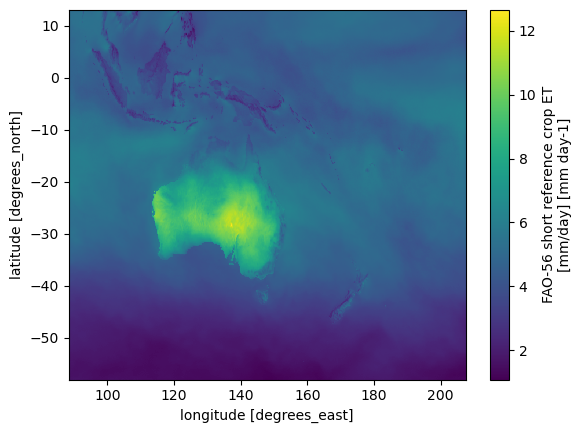

In [12]:
et0.et0.mean("time").plot()

### Comparison with previously calculated BARRAR2 data

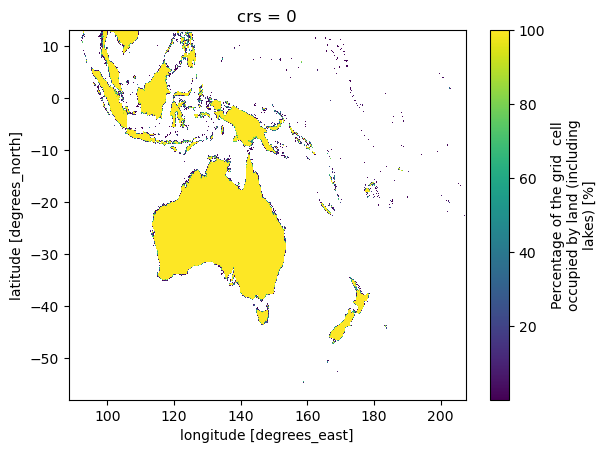

In [9]:
sftlf = xr.open_dataset("/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/sftlf/latest/sftlf_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc").sftlf
ls_mask = np.ma.masked_greater(sftlf,99)
sftlf.where(ls_mask).plot()

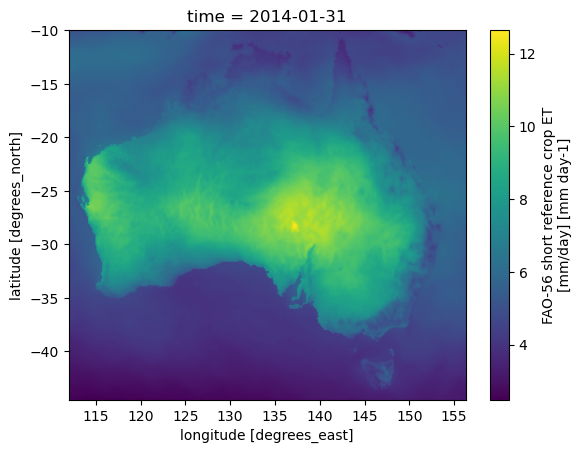

In [22]:
barrar2_et0_acs_files = sorted(
    glob.glob(
        "/g/data/ia39/ncra/drought_aridity/ai/"
        "acs_downscaled_notBC_5km/pet_FAO56/"
        "BOM/ERA5/historical/*2014*.nc"
    )
)
barrar2_et0_acs_files
barrar2_et0_acs = xr.open_dataset(
    barrar2_et0_acs_files[0]
)
barrar2_et0_acs = barrar2_et0_acs.isel(time=0)
barrar2_et0_acs.ET0.plot()

-57.97 12.98
88.48 207.39
-44.5 -10.0
112.0 156.25


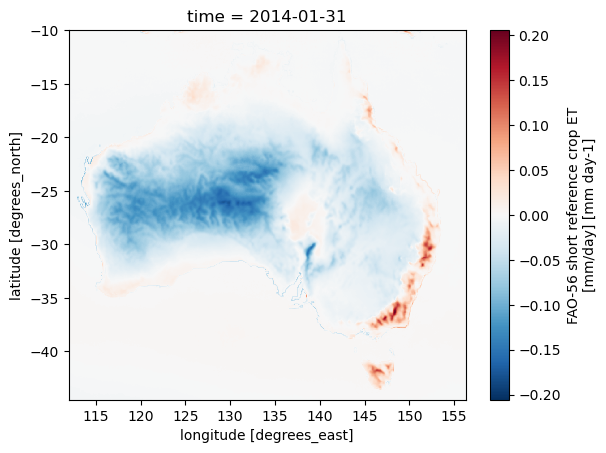

In [41]:
print(et0_mean.lat.min().values, et0_mean.lat.max().values)
print(et0_mean.lon.min().values, et0_mean.lon.max().values)

print(barrar2_et0_acs.lat.min().values, barrar2_et0_acs.lat.max().values)
print(barrar2_et0_acs.lon.min().values, barrar2_et0_acs.lon.max().values)

et0_regrid = et0_mean.interp(
    lat=barrar2_et0_acs.lat,
    lon=barrar2_et0_acs.lon,
    method="linear",
)

diff = barrar2_et0_acs.ET0 - et0_regrid.et0
diff.plot()

### Checking interim calculations

In [16]:
### Convert variables to FAO-56 compliant units and calculate mean temperature
tasmax = standardise_units(da_tasmax, "temperature")
tasmin = standardise_units(da_tasmin, "temperature")
rsds = standardise_units(da_rsds, "radiation")
sfcWind = standardise_units(da_sfcWind, "wind")
hurs = standardise_units(da_hurs, "relative_humidity")
ps = standardise_units(da_ps, "pressure")
orog = standardise_units(da_orog, "elevation")

tasmean = meanVar(tasmax,tasmin)

In [17]:
check_units(rsds, "radiation")
check_units(tasmax, "temperature")
check_units(tasmin, "temperature")
check_units(sfcWind, "wind")
check_units(hurs, "relative_humidity")
check_units(ps, "pressure")
check_units(orog, "elevation")

rsds: W m-2
tasmax: degC
tasmin: degC
sfcWind: m s-1
hurs: %
ps: kPa
orog: m


In [7]:
### Extra-terrestrial radiation ([MJ/m2/day])
Ra = extraTerrRadiation(rsds, lat_name='lat')
Ra
# check_units(Ra,"extraterr_radiation")

<xarray.DataArray (time: 31, lat: 646)> Size: 160kB
array([[43.69065822, 43.69773432, 43.70486253, ..., 29.76597834,
        29.70900133, 29.6519405 ],
       [43.59727674, 43.60470203, 43.61217747, ..., 29.80359381,
        29.7467393 , 29.68980064],
       [43.49599443, 43.5037955 , 43.51164466, ..., 29.84397973,
        29.78725847, 29.7304527 ],
       ...,
       [38.35327004, 38.3779344 , 38.40257173, ..., 31.73237322,
        31.68290919, 31.63334426],
       [38.07170095, 38.09719025, 38.12264965, ..., 31.83046619,
        31.78142656, 31.7322852 ],
       [37.78501643, 37.81133645, 37.83762374, ..., 31.92984083,
        31.88123613, 31.83252888]], shape=(31, 646))
Coordinates:
  * time     (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 2025-01-31T12...
  * lat      (lat) float64 5kB -57.97 -57.86 -57.75 -57.64 ... 12.76 12.87 12.98
    crs      int32 4B 0
Attributes:
    axis:           T
    standard_name:  time
    long_name:      time
    bounds:         time_bnds
    units:          MJ m-2 day-1

In [8]:
### 2-meter wind speed [m s-1]
wind_2m = wind2m(sfcWind,scaling_factor="log_wind")
wind_2m 

<xarray.DataArray 'sfcWind' (time: 31, lat: 646, lon: 1082)> Size: 173MB
array([[[2.48781383, 2.48197046, 2.49219636, ..., 5.86381956,
         5.90472314, 5.94416587],
        [2.52579572, 2.51556983, 2.52579572, ..., 5.80830757,
         5.84190693, 5.88134967],
        [2.54186498, 2.53309993, 2.54624751, ..., 5.74110884,
         5.76448231, 5.79662083],
        ...,
        [5.33353394, 5.31454299, 5.29701289, ..., 5.06327818,
         5.06181733, 5.04720892],
        [5.29993457, 5.28532615, 5.2765611 , ..., 5.12463354,
         5.13193775, 5.13339859],
        [5.28678699, 5.26633521, 5.25464847, ..., 5.18160637,
         5.19329311, 5.19767564]],

       [[4.48770645, 4.45995045, 4.41904688, ..., 5.35836825,
         5.43579287, 5.50883497],
        [4.53153171, 4.50231487, 4.45995045, ..., 5.24588342,
         5.32915141, 5.39781098],
        [4.56513107, 4.53883592, 4.49939319, ..., 5.1129468 ,
         5.20059732, 5.2765611 ],
...
        [3.2284607 , 3.22407817, 3.19778301, ..., 6.39848771,
         6.37803593, 6.34735825],
        [3.13058429, 3.1276626 , 3.10282829, ..., 6.41163529,
         6.38826182, 6.35466246],
        [3.01079525, 2.99910851, 2.98303925, ..., 6.42186118,
         6.4014094 , 6.36050582]],

       [[6.40725277, 6.45984307, 6.49636412, ..., 5.58333791,
         5.59648549, 5.59794633],
        [6.46276476, 6.51243338, 6.5547978 , ..., 5.49130487,
         5.48984402, 5.4752356 ],
        [6.52558096, 6.57378875, 6.61615316, ..., 5.34083815,
         5.31016047, 5.26195268],
        ...,
        [3.06922892, 3.1276626 , 3.18609628, ..., 6.23487342,
         6.19981321, 6.16037048],
        [3.03562956, 3.09114155, 3.14227102, ..., 6.22318668,
         6.19835237, 6.16767469],
        [3.01225609, 3.05900303, 3.10867166, ..., 6.21442163,
         6.19396984, 6.17205721]]], shape=(31, 646, 1082))
Coordinates:
  * time     (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 2025-01-31T12...
  * lat      (lat) float64 5kB -57.97 -57.86 -57.75 -57.64 ... 12.76 12.87 12.98
  * lon      (lon) float64 9kB 88.48 88.59 88.7 88.81 ... 207.2 207.3 207.4
    height   float64 8B ...
    crs      int32 4B ...
Attributes:
    long_name:      Near-Surface Wind Speed
    standard_name:  wind_speed
    units:          m s-1
    cell_methods:   time: point (interval: 1 hour) area: interpolation (metho...
    grid_mapping:   crs

In [9]:
esat = satVapourPressure(tasmax, tasmin)
check_units(esat,"vapour_pressure")
esat

None: kPa


<xarray.DataArray (time: 31, lat: 646, lon: 1082)> Size: 173MB
array([[[0.6819434 , 0.68385414, 0.68312352, ..., 0.66336032,
         0.66336032, 0.66410777],
        [0.68118994, 0.68159153, 0.68086989, ..., 0.66451946,
         0.66449416, 0.66449416],
        [0.67819107, 0.67710662, 0.67716325, ..., 0.66604351,
         0.6656556 , 0.66562988],
        ...,
        [3.42028869, 3.42336213, 3.42167037, ..., 3.11996438,
         3.11124703, 3.09978408],
        [3.38906136, 3.39668016, 3.39805648, ..., 3.11842043,
         3.11266803, 3.10261336],
        [3.36563846, 3.37481084, 3.373064  , ..., 3.10564178,
         3.10415937, 3.09978408]],

       [[0.68972009, 0.69051024, 0.68941363, ..., 0.69660583,
         0.69660583, 0.69621095],
        [0.68858597, 0.68864104, 0.68830616, ..., 0.69703584,
         0.69740796, 0.69894966],
        [0.68785011, 0.68753467, 0.68611029, ..., 0.69588585,
         0.6962688 , 0.69703584],
...
        [3.58204873, 3.58712956, 3.59230646, ..., 3.29051791,
         3.28895844, 3.29047116],
        [3.58706535, 3.58552019, 3.57742072, ..., 3.29354213,
         3.29351997, 3.29501667],
        [3.5773514 , 3.57722063, 3.57715916, ..., 3.30114259,
         3.29657124, 3.29655153]],

       [[0.74009052, 0.73976545, 0.73866162, ..., 0.86909292,
         0.86671557, 0.86577001],
        [0.74338852, 0.74345739, 0.74191586, ..., 0.8705261 ,
         0.87050692, 0.87095479],
        [0.74504238, 0.74507646, 0.74514708, ..., 0.87334171,
         0.87426065, 0.87521439],
        ...,
        [3.63204832, 3.63374866, 3.64048007, ..., 3.27233284,
         3.26777122, 3.26474322],
        [3.62194584, 3.62703069, 3.62880762, ..., 3.27837413,
         3.27230343, 3.26777122],
        [3.61356516, 3.62201974, 3.62379258, ..., 3.28291977,
         3.27533755, 3.27233284]]], shape=(31, 646, 1082))
Coordinates:
  * time     (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 2025-01-31T12...
  * lat      (lat) float64 5kB -57.97 -57.86 -57.75 -57.64 ... 12.76 12.87 12.98
  * lon      (lon) float64 9kB 88.48 88.59 88.7 88.81 ... 207.2 207.3 207.4
    height   float64 8B 1.5
    crs      int32 4B 0
Attributes:
    standard_name:  air_temperature
    units:          kPa
    grid_mapping:   crs

In [10]:
### Actual vapour pressure [kPa]
ea = actVapourPressure(esat, hurs=hurs)
check_units(ea,"vapour_pressure")
ea

None: kPa


<xarray.DataArray (time: 31, lat: 646, lon: 1082)> Size: 173MB
array([[[0.54555222, 0.543831  , 0.54159304, ..., 0.5539083 ,
         0.55330219, 0.55327344],
        [0.54825521, 0.54531482, 0.54460491, ..., 0.55375838,
         0.55355884, 0.55347448],
        [0.54961045, 0.54755088, 0.54743177, ..., 0.55554305,
         0.55520325, 0.55522608],
        ...,
        [2.21735287, 2.21581418, 2.2145876 , ..., 2.36222855,
         2.36202973, 2.3619053 ],
        [2.21500934, 2.21850441, 2.22079708, ..., 2.36393551,
         2.36916897, 2.37010574],
        [2.21398165, 2.22185895, 2.22271618, ..., 2.35344488,
         2.36187612, 2.36747144]],

       [[0.53007793, 0.52845148, 0.52654219, ..., 0.6355342 ,
         0.63728166, 0.63832354],
        [0.53113371, 0.52885186, 0.52792377, ..., 0.62829544,
         0.63058977, 0.63416542],
        [0.53308426, 0.53079154, 0.52921951, ..., 0.62162985,
         0.62382098, 0.62643246],
...
        [2.87010343, 2.86867901, 2.86373303, ..., 2.81953843,
         2.82588859, 2.83667374],
        [2.85698458, 2.85428985, 2.84595784, ..., 2.81592424,
         2.82115394, 2.83279324],
        [2.8539596 , 2.85024835, 2.84813395, ..., 2.81514888,
         2.81727063, 2.82707664]],

       [[0.63007523, 0.62923454, 0.62935242, ..., 0.86415016,
         0.8628565 , 0.86243037],
        [0.63334079, 0.63395624, 0.63369866, ..., 0.86676697,
         0.86722817, 0.86758878],
        [0.63396904, 0.63484298, 0.63607836, ..., 0.87048992,
         0.8713621 , 0.87154078],
        ...,
        [2.76626678, 2.75776772, 2.75689929, ..., 2.72292884,
         2.72380619, 2.72827441],
        [2.77110469, 2.76670671, 2.75863577, ..., 2.71471348,
         2.71661702, 2.7202181 ],
        [2.77588367, 2.77548095, 2.7695516 , ..., 2.70920229,
         2.70779296, 2.71403698]]], shape=(31, 646, 1082))
Coordinates:
  * time                (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 20...
  * lat                 (lat) float64 5kB -57.97 -57.86 -57.75 ... 12.87 12.98
  * lon                 (lon) float64 9kB 88.48 88.59 88.7 ... 207.2 207.3 207.4
    height              float64 8B 1.5
    level_height        float64 8B ...
    model_level_number  int32 4B ...
    sigma               float64 8B ...
    crs                 int32 4B 0
Attributes:
    long_name:     Near-Surface Relative Humidity
    cell_methods:  time: point (interval: 1 hour) time: mean (interval: 1 day)
    grid_mapping:  crs
    units:         kPa

In [11]:
Rn = netRadiation(rsds, orog, tasmax, tasmin, ea)
check_units(Rn,"net_radiation")
Rn

<xarray.DataArray (time: 31, lat: 646, lon: 1082)> Size: 173MB
array([[[32.85421258, 32.85421429, 32.85421591, ..., 32.85682428,
         32.85681817, 32.85681221],
        [32.85953766, 32.85953923, 32.8595411 , ..., 32.8621569 ,
         32.86215118, 32.86214599],
        [32.86490189, 32.86490351, 32.86490541, ..., 32.86752792,
         32.86752283, 32.86751811],
        ...,
        [22.38475517, 22.38475409, 22.38475284, ..., 22.38479692,
         22.38479673, 22.38479742],
        [22.34191149, 22.34190991, 22.34190833, ..., 22.34195087,
         22.34195072, 22.34195129],
        [22.29900449, 22.29900258, 22.29900033, ..., 22.29904181,
         22.29904156, 22.29904212]],

       [[32.78472281, 32.78471895, 32.78471509, ..., 32.7869278 ,
         32.78692271, 32.78691757],
        [32.79031669, 32.79031252, 32.79030872, ..., 32.79252489,
         32.79251996, 32.79251543],
        [32.79594832, 32.79594399, 32.79593996, ..., 32.79816014,
         32.79815535, 32.79815109],
...


<xarray.DataArray (time: 31, lat: 646, lon: 1082)> Size: 173MB
array([[[14.76622374, 15.72011075, 15.14704627, ..., 13.17340379,
         13.38836577, 13.3712526 ],
        [15.49958503, 15.86368085, 15.53141042, ..., 13.74054887,
         13.65094483, 13.9491584 ],
        [14.70787468, 15.81424608, 15.33459516, ..., 12.49130313,
         14.25268235, 13.47181006],
        ...,
        [ 9.6452576 ,  9.4956873 ,  8.45359617, ..., 11.06587181,
         11.37563129, 10.89701848],
        [ 8.82345694,  9.80626671,  9.69644241, ..., 11.32176737,
         11.01863916, 10.73774452],
        [ 9.9652767 , 10.2843153 ,  9.77548184, ..., 10.66518038,
         10.38133114, 10.83758497]],

       [[17.59948846, 17.0588026 , 16.42079129, ..., 14.65088816,
         15.18450357, 14.49167907],
        [16.79653312, 17.15144787, 16.54951499, ..., 13.27620389,
         13.66552916, 13.24866866],
        [15.74605191, 16.96984618, 17.0156643 , ..., 12.97264047,
         13.74612502, 12.93746394],
...
        [10.83412366, 12.29257429, 11.8774443 , ..., 11.23743522,
         13.03547998, 12.44325524],
        [11.53743005, 12.30981673, 11.02218075, ..., 12.92187447,
         12.68195679, 12.25803066],
        [11.95006976, 11.77883108, 11.8645927 , ..., 13.03973334,
         12.75635156, 12.06068848]],

       [[10.39842467,  9.91803806, 10.7036697 , ...,  8.02001547,
          8.57738896,  8.19891814],
        [ 9.66880307, 10.26249011, 10.36398436, ...,  8.74495452,
          8.12108435,  8.65299609],
        [10.80310964,  9.97139357, 10.74283371, ...,  8.29876245,
          8.58701593,  8.51568066],
        ...,
        [12.96696713, 11.82256558, 12.00486219, ..., 13.47393502,
         13.52238309, 13.1999353 ],
        [11.61218243, 12.34654995, 11.64273948, ..., 13.2648894 ,
         13.50974152, 13.56376591],
        [12.53523805, 12.70086745, 12.4742595 , ..., 13.36930918,
         13.07370314, 13.20157498]]], shape=(31, 646, 1082))
Coordinates:
  * time                (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 20...
  * lat                 (lat) float64 5kB -57.97 -57.86 -57.75 ... 12.87 12.98
  * lon                 (lon) float64 9kB 88.48 88.59 88.7 ... 207.2 207.3 207.4
    crs                 int32 4B 0
    height              float64 8B 1.5
    level_height        float64 8B ...
    model_level_number  int32 4B ...
    sigma               float64 8B ...
Attributes:
    long_name:      Surface Downwelling Shortwave Radiation
    standard_name:  surface_downwelling_shortwave_flux_in_air
    grid_mapping:   crs
    axis:           T
    bounds:         time_bnds
    units:          MJ m-2 day-1

In [13]:
et0 = calculate_daily_et0(Rn,tasmean,wind_2m,esat,ea,ps,crop="short",co2=None)
et0

Files read. Start calculation...


<xarray.Dataset> Size: 173MB
Dimensions:  (time: 31, lat: 646, lon: 1082)
Coordinates:
  * time     (time) datetime64[ns] 248B 2025-01-01T12:00:00 ... 2025-01-31T12...
  * lat      (lat) float64 5kB -57.97 -57.86 -57.75 -57.64 ... 12.76 12.87 12.98
  * lon      (lon) float64 9kB 88.48 88.59 88.7 88.81 ... 207.2 207.3 207.4
Data variables:
    ET0      (time, lat, lon) float64 173MB 6.011 6.4 6.166 ... 5.332 5.384

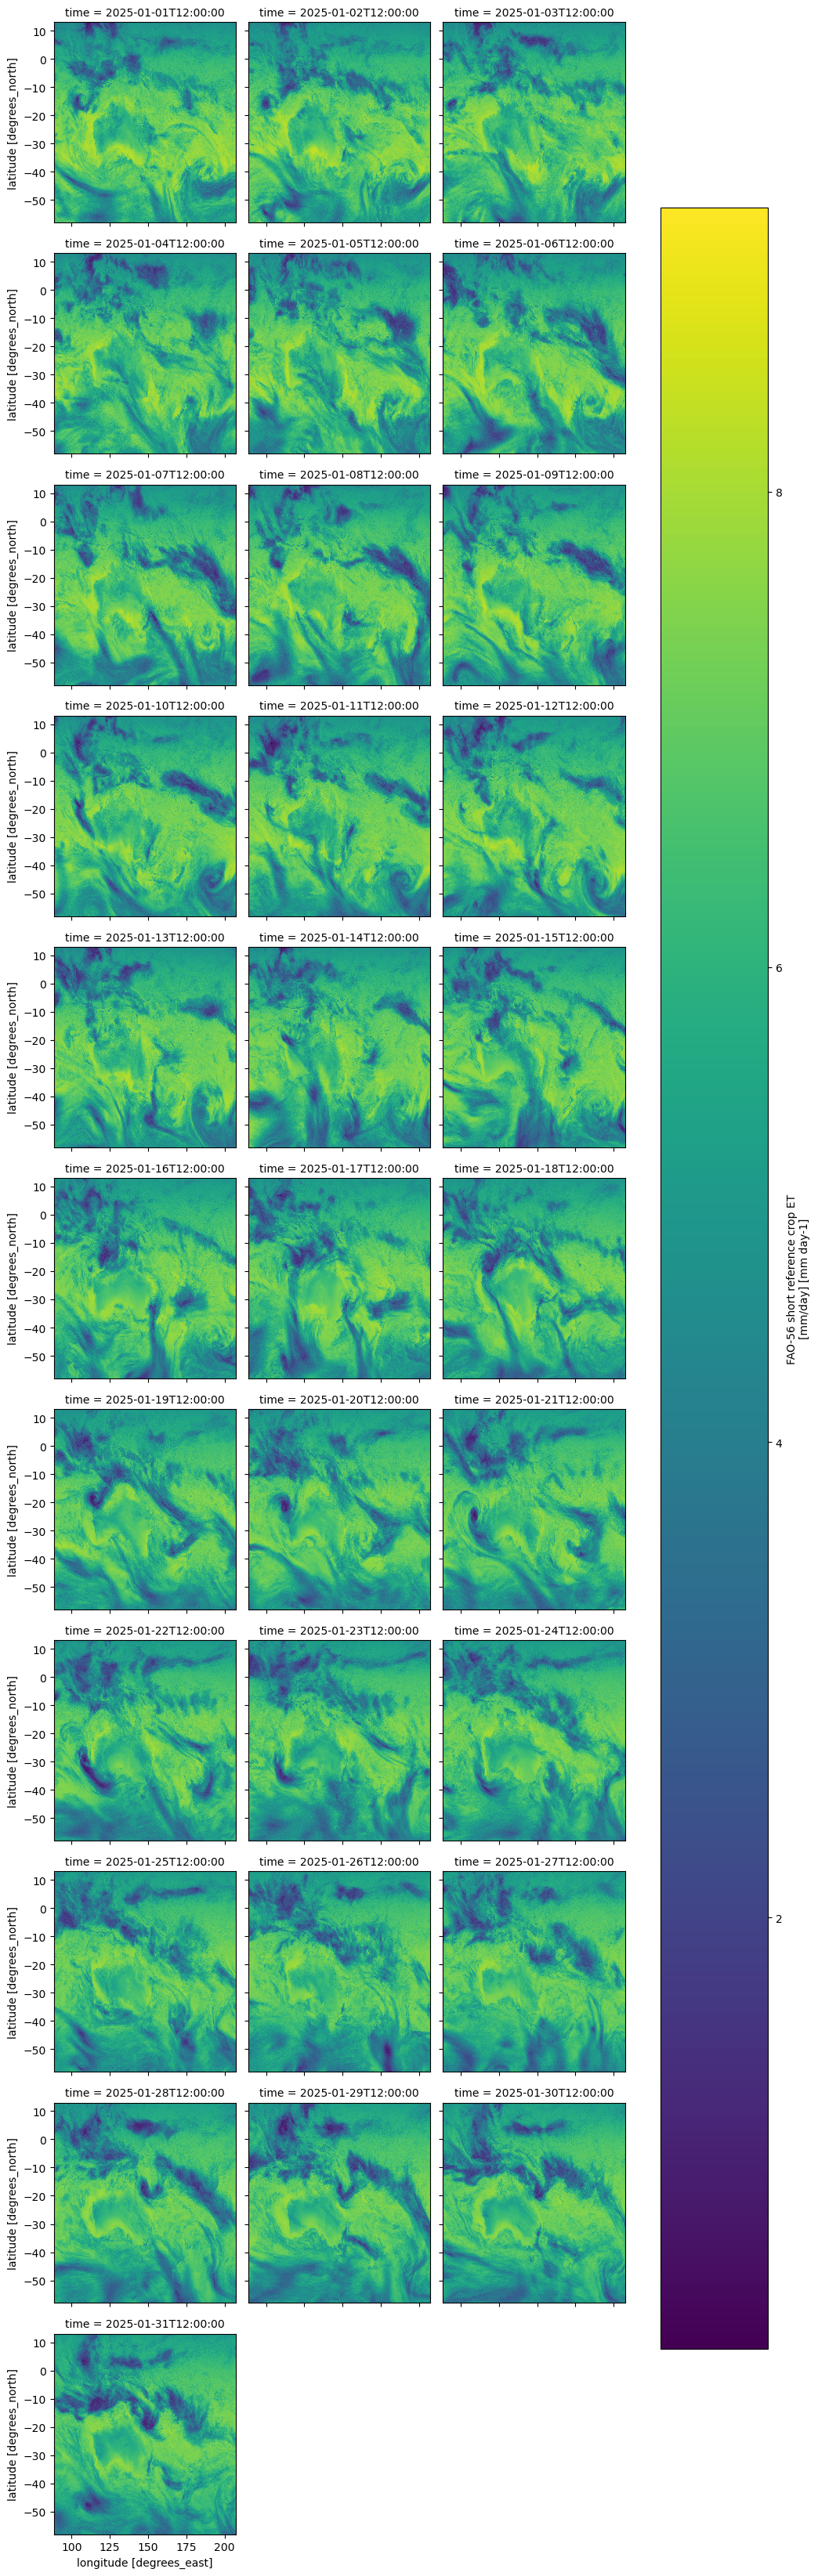

In [14]:
et0.ET0.plot(col="time",col_wrap=3)